# Annual report: page layout check

The target document, `2026-Annual-Report-Web.pdf`, mixes wide two-page spreads with normal pages.
This notebook checks whether the current parsing (`parse_pdf` in `ingest.py`: Unstructured `hi_res`) reads
those pages in a sensible order, before the whole 175-page report is ingested.

It answers four questions:

1. Which pages are spreads, and which are normal pages?
2. On a spread, does Unstructured mix text from the left and right halves into one element?
3. On multi-column pages, are the columns read in order?
4. Do the chunks built from these pages stay coherent?

Only a sample of pages is parsed, with the same settings as the pipeline. No model is called.

In [1]:
import sys
import tempfile
import time
from collections import Counter
from pathlib import Path

from IPython.display import display
from pdf2image import convert_from_path
from PIL import ImageDraw
from pypdf import PdfReader, PdfWriter

PROJECT_ROOT = Path.cwd().parent  # this notebook lives in notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

from multimodal_rag.ingest import parse_pdf, split_into_chunks

REPORT_PATH = PROJECT_ROOT / "2026-Annual-Report-Web.pdf"

/home/aikosh/multimodal-rag-pipeline/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Page sizes

`pdfinfo` reports only the first page's size (1188 x 774 points, a wide spread), but the pages differ.
The size below is the visible area (the crop box), in points.

In [2]:
reader = PdfReader(REPORT_PATH)

pages_by_size = {}
for number, page in enumerate(reader.pages, start=1):
    size = f"{round(float(page.cropbox.width))} x {round(float(page.cropbox.height))}"
    pages_by_size.setdefault(size, []).append(number)

for size, numbers in pages_by_size.items():
    print(f"{size:>11}: {len(numbers):3} pages  {numbers if len(numbers) < 20 else str(numbers[:3]) + ' ... ' + str(numbers[-3:])}")

 1188 x 774:  12 pages  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 175]
  594 x 774: 162 pages  [12, 13, 14] ... [172, 173, 174]
  774 x 594:   1 pages  [142]


## 2. Parse a sample of pages

| Page | Why it was picked |
|---|---|
| 3, 4, 8 | Wide spreads with text and diagrams on both halves |
| 13 | Shareholder letter, three text columns |
| 26 | Normal page with a table (director nominees) |
| 128 | Text layer looks garbled in `pdftotext` (a font encoding problem) |
| 139 | Consolidated Statements of Income, the main financial table |
| 142 | The only landscape page, a wide equity table |

The sample is copied into a small PDF and parsed with `parse_pdf` from `ingest.py`, so the settings match the pipeline.

In [3]:
SAMPLE_PAGES = [3, 4, 8, 13, 26, 128, 139, 142]

sample_path = Path(tempfile.mkdtemp()) / "sample.pdf"
writer = PdfWriter()
for page_number in SAMPLE_PAGES:
    writer.add_page(reader.pages[page_number - 1])
writer.write(sample_path)

start = time.time()
elements = parse_pdf(sample_path)
print(f"{len(elements)} elements from {len(SAMPLE_PAGES)} pages in {time.time() - start:.0f}s")


def original_page(element):
    """Page number in the full report. The sample PDF numbers its pages 1, 2, 3..."""
    return SAMPLE_PAGES[element.metadata.page_number - 1]


for page_number in SAMPLE_PAGES:
    on_page = [element for element in elements if original_page(element) == page_number]
    categories = Counter(element.category for element in on_page)
    print(f"page {page_number:3}: {len(on_page):3} elements  {dict(categories)}")

No languages specified, defaulting to English.


*************** EP Error ***************
EP Error /onnxruntime_src/onnxruntime/python/onnxruntime_pybind_state.cc:573 void onnxruntime::python::RegisterTensorRTPluginsAsCustomOps(PySessionOptions&, const onnxruntime::ProviderOptions&) Please install TensorRT libraries as mentioned in the GPU requirements page, make sure they're in the PATH or LD_LIBRARY_PATH, and that your GPU is supported.
 when using ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Falling back to ['CUDAExecutionProvider', 'CPUExecutionProvider'] and retrying.
****************************************


Loading weights: 100%|██████████| 367/367 [00:00<00:00, 7347.05it/s]


190 elements from 8 pages in 67s
page   3:  10 elements  {'Image': 2, 'Title': 3, 'NarrativeText': 5}
page   4:  25 elements  {'Title': 2, 'UncategorizedText': 17, 'NarrativeText': 4, 'Image': 2}
page   8:  20 elements  {'Title': 2, 'UncategorizedText': 14, 'NarrativeText': 3, 'Image': 1}
page  13:  16 elements  {'NarrativeText': 14, 'Title': 2}
page  26:  36 elements  {'Title': 2, 'UncategorizedText': 24, 'NarrativeText': 6, 'Table': 2, 'ListItem': 2}
page 128:  14 elements  {'NarrativeText': 4, 'Table': 3, 'Title': 3, 'UncategorizedText': 3, 'Footer': 1}
page 139:  29 elements  {'Title': 1, 'UncategorizedText': 25, 'Table': 1, 'NarrativeText': 1, 'Footer': 1}
page 142:  40 elements  {'Title': 1, 'UncategorizedText': 36, 'Table': 1, 'NarrativeText': 1, 'Footer': 1}


## 3. Reading order, drawn on the page

Each box is one element, numbered in the order Unstructured returns them. On spreads, the red line marks the middle.
Boxes are coloured by type: blue for text, green for titles, orange for tables, purple for images.

Page 3


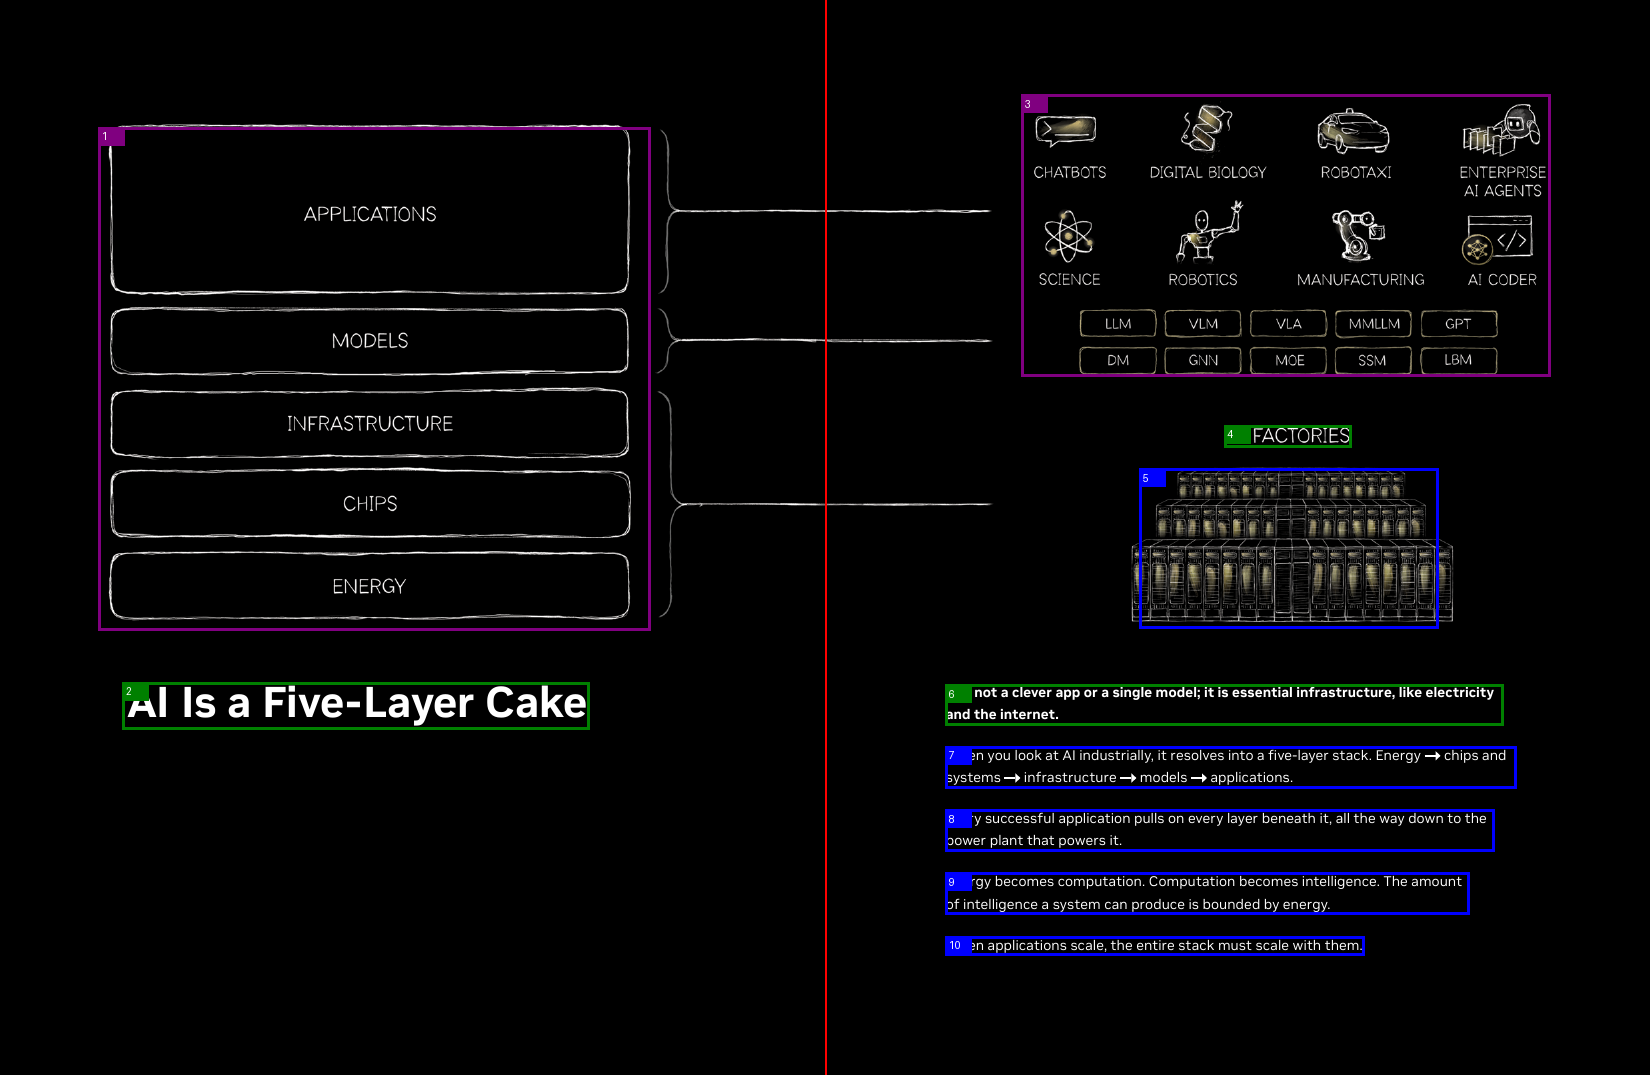

Page 4


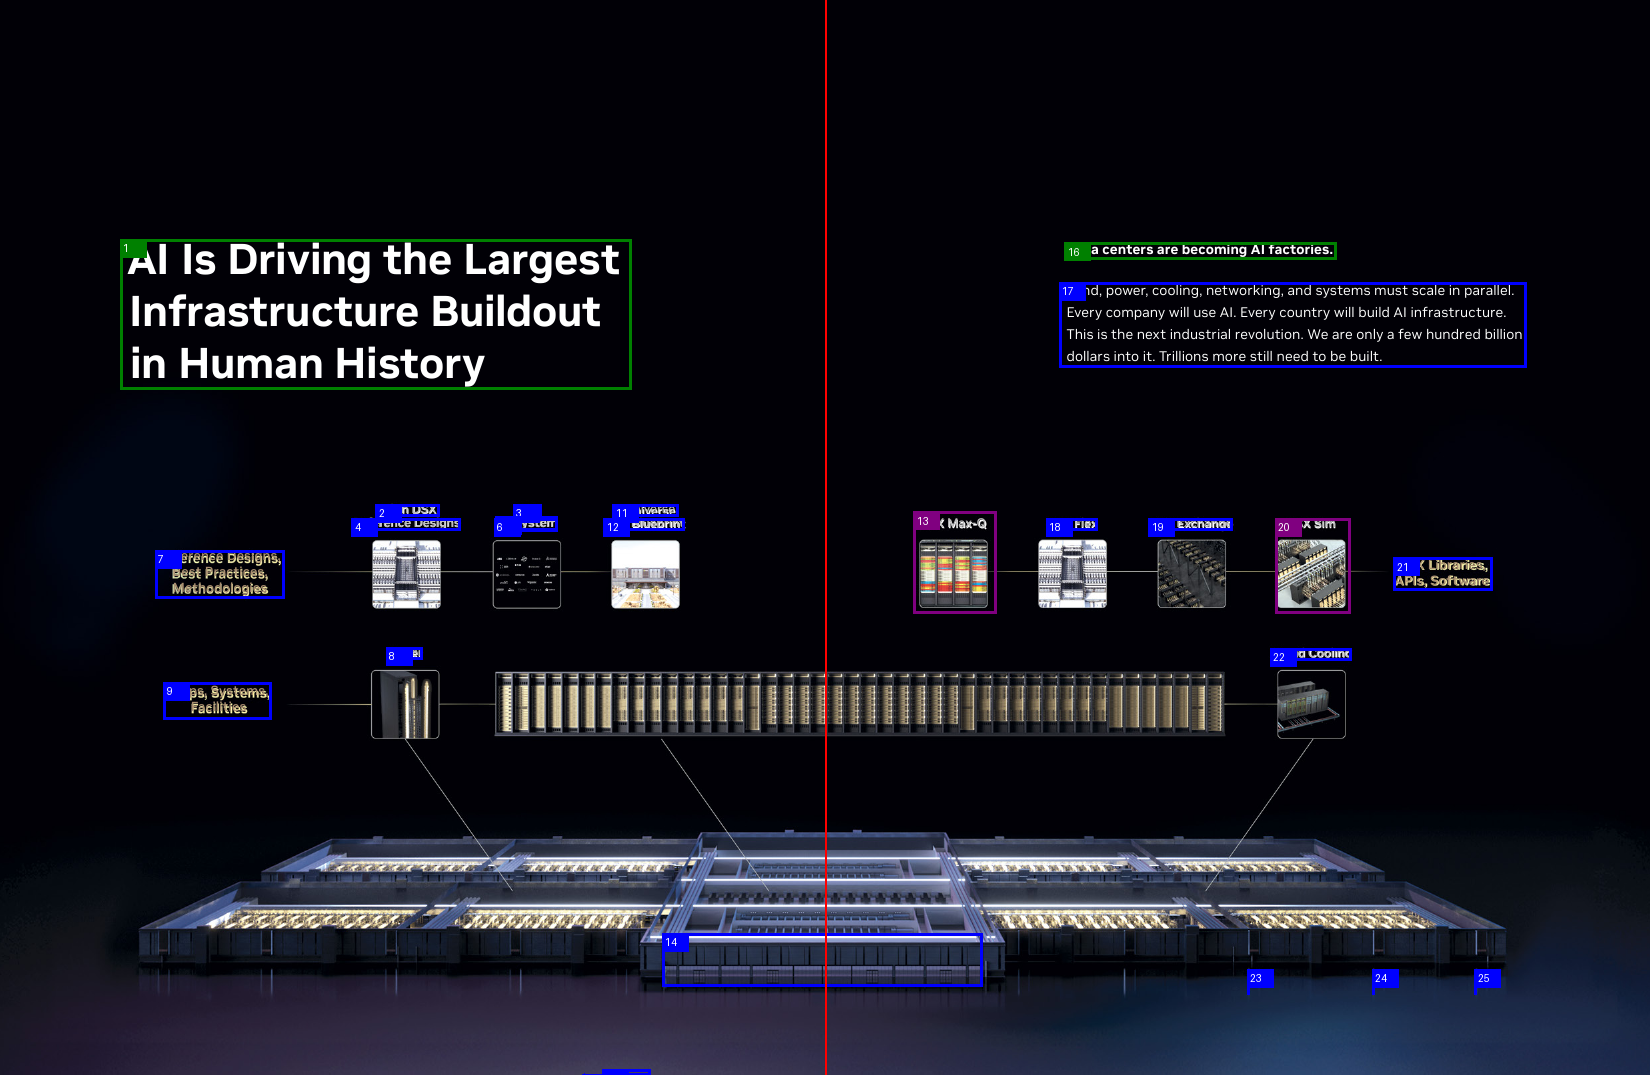

Page 8


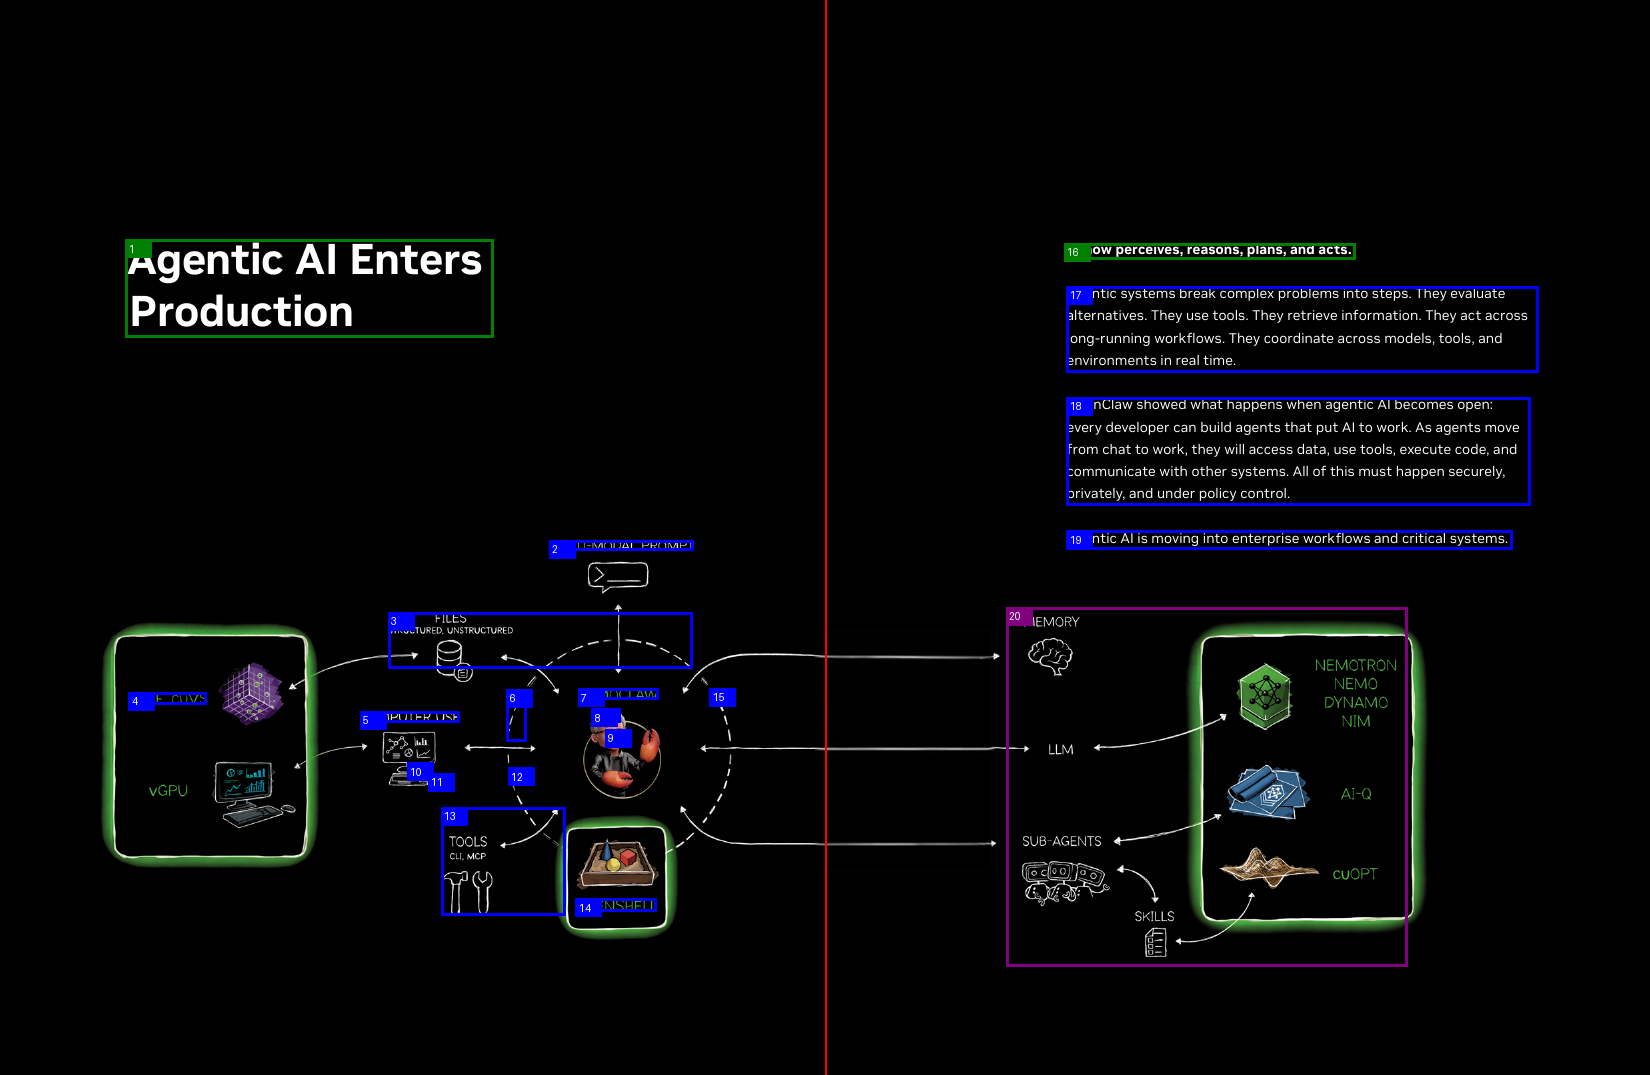

Page 13


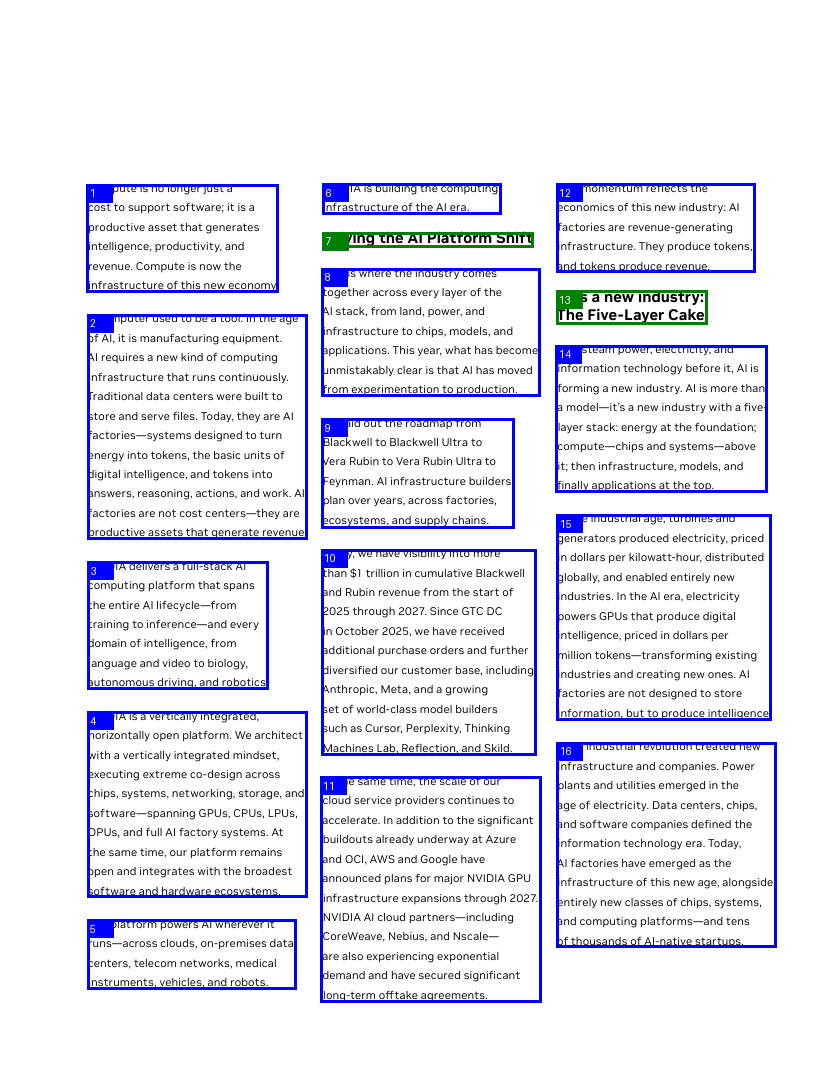

Page 26


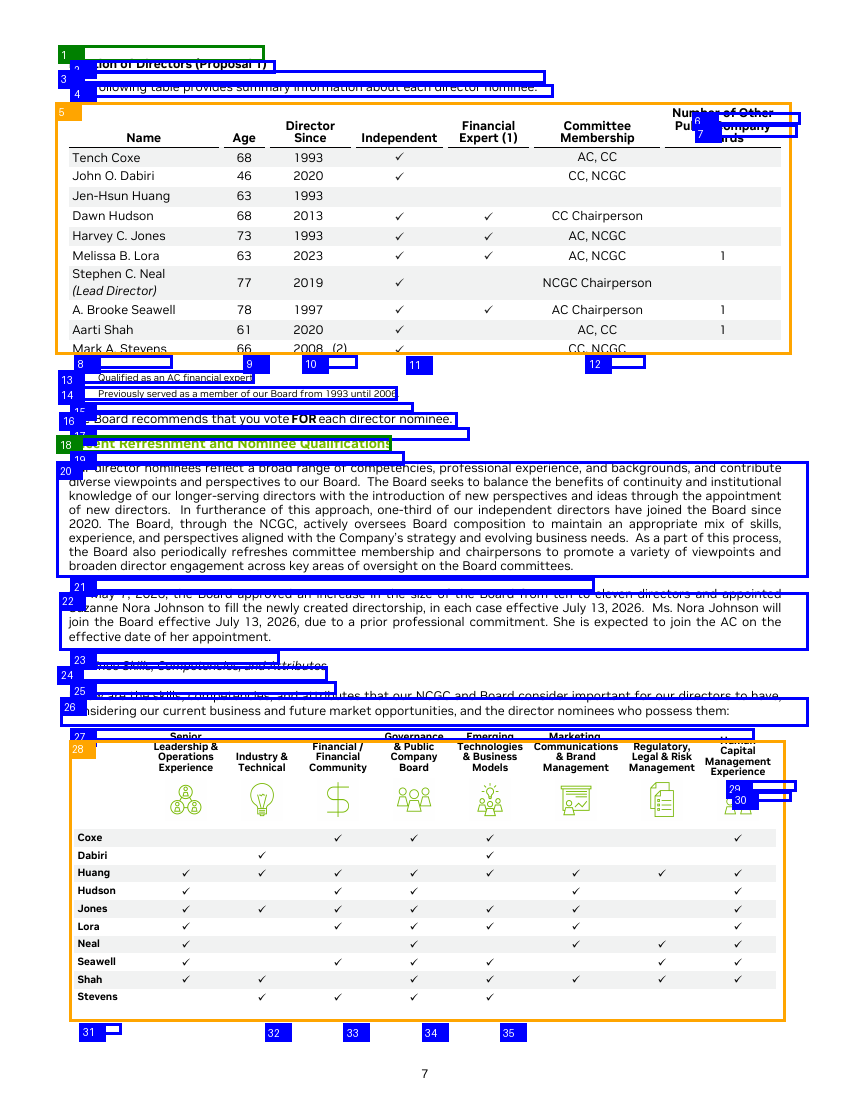

Page 128


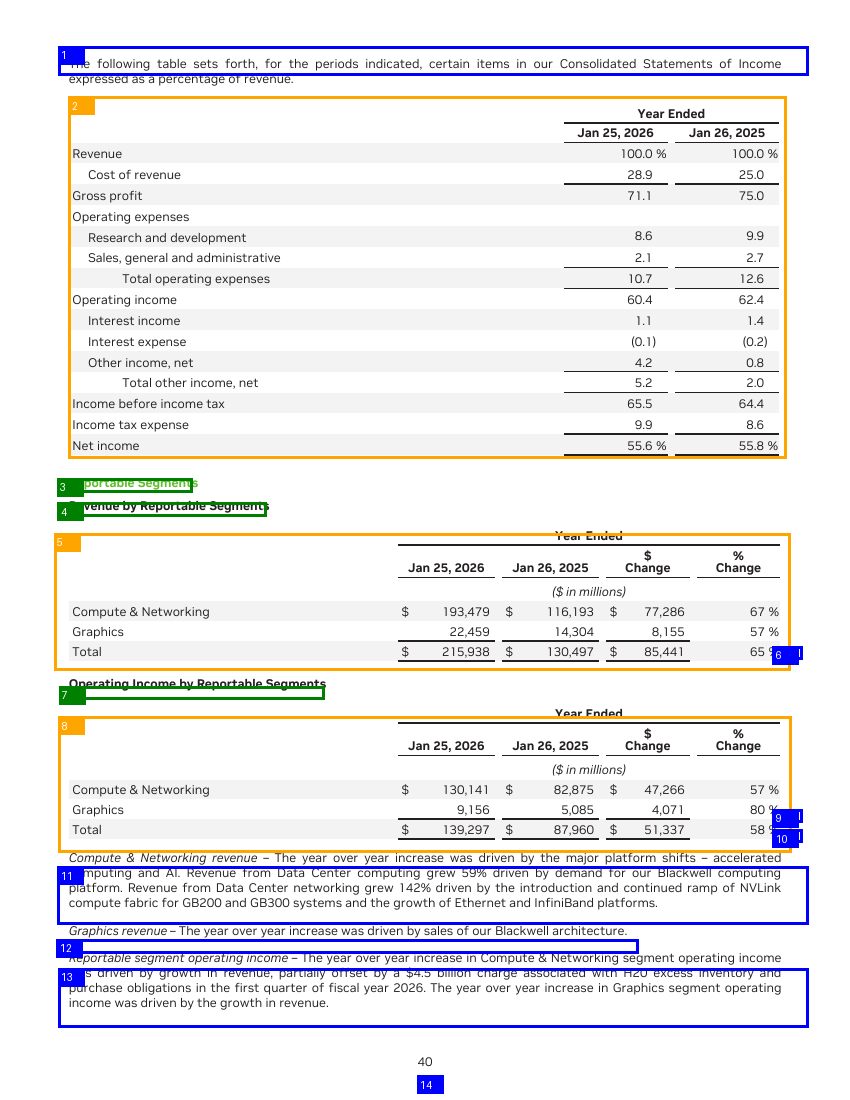

Page 139


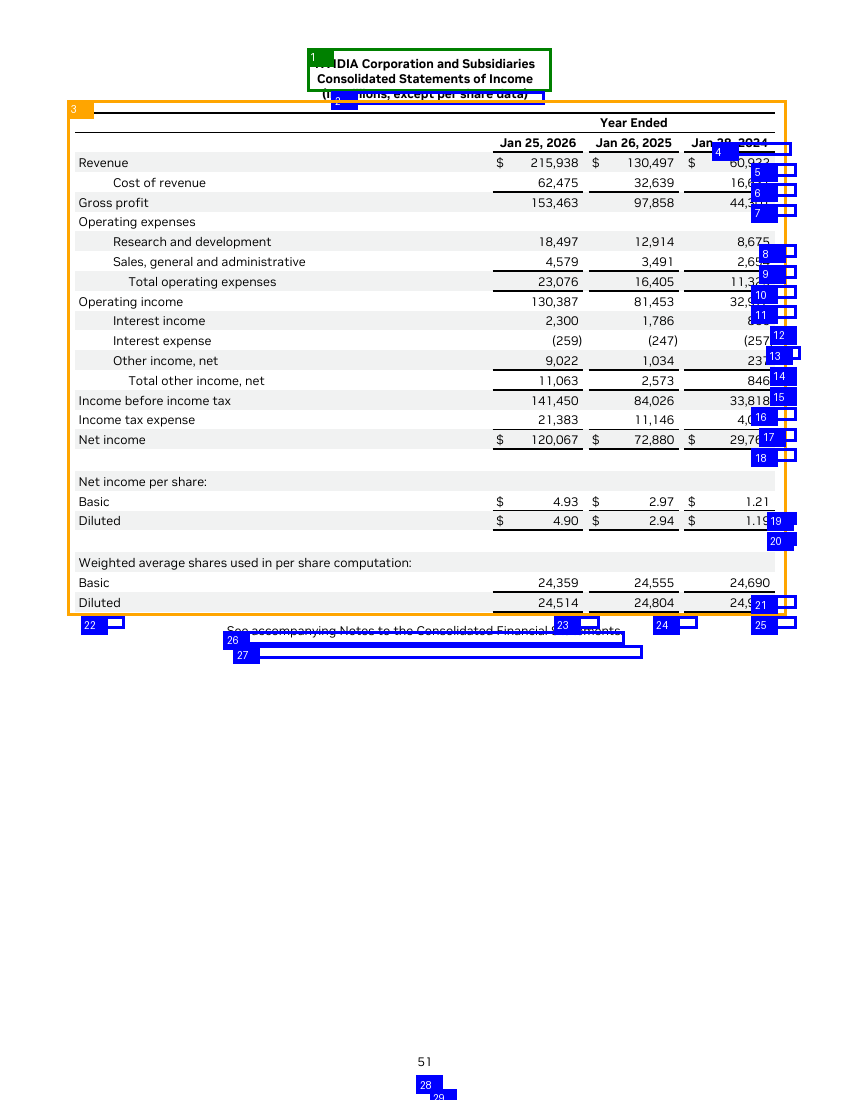

Page 142


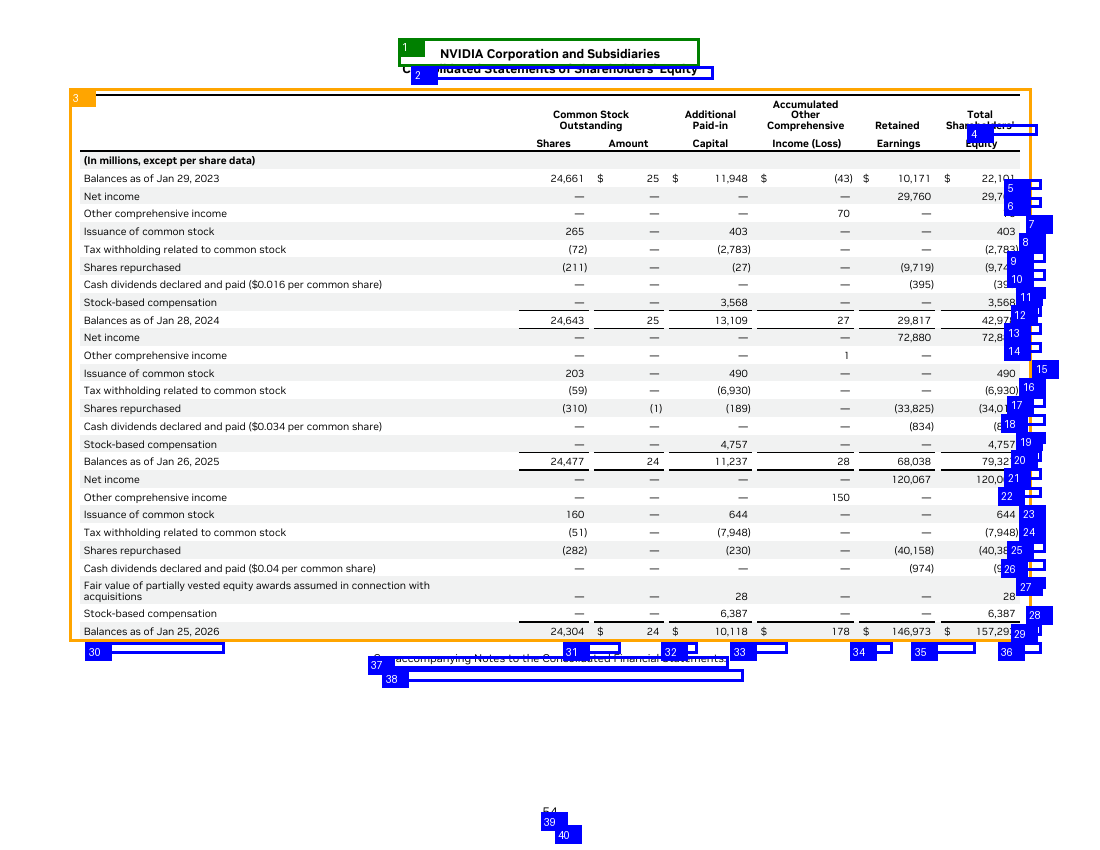

In [4]:
COLOURS = {"Title": "green", "Table": "orange", "Image": "purple"}


def is_spread(page_number):
    page = reader.pages[page_number - 1]
    return float(page.cropbox.width) > 1000


def box_of(element):
    """The element's box as (left, top, right, bottom) in the coordinate space Unstructured used."""
    points = element.metadata.coordinates.points
    xs = [x for x, _ in points]
    ys = [y for _, y in points]
    return min(xs), min(ys), max(xs), max(ys)


def draw_reading_order(page_number):
    on_page = [e for e in elements if original_page(e) == page_number and e.metadata.coordinates.points]
    image = convert_from_path(REPORT_PATH, dpi=100, first_page=page_number, last_page=page_number)[0]
    system = on_page[0].metadata.coordinates.system
    scale = image.width / system.width

    draw = ImageDraw.Draw(image)
    for order, element in enumerate(on_page, start=1):
        left, top, right, bottom = (value * scale for value in box_of(element))
        colour = COLOURS.get(element.category, "blue")
        draw.rectangle([left, top, right, bottom], outline=colour, width=3)
        draw.rectangle([left, top, left + 26, top + 18], fill=colour)
        draw.text((left + 3, top + 3), str(order), fill="white")
    if is_spread(page_number):
        draw.line([image.width / 2, 0, image.width / 2, image.height], fill="red", width=2)

    print(f"Page {page_number}")
    display(image)


for page_number in SAMPLE_PAGES:
    draw_reading_order(page_number)

## 4. Reading order as text

For every element: its position in the order, its type, where it sits across the page (0 = left edge, 1 = right edge),
and the start of its text.

- **Spreads:** an element whose box crosses the middle is flagged `CROSSES MIDDLE`. Its text may join lines from both halves.
- **Multi-column pages:** a jump back to an earlier column is counted. Zero jumps means the columns were read left to right.

In [5]:
COLUMN_COUNT = {13: 3}  # pages with several text columns


def show_order(page_number):
    on_page = [e for e in elements if original_page(e) == page_number and e.metadata.coordinates.points]
    width = on_page[0].metadata.coordinates.system.width
    columns = COLUMN_COUNT.get(page_number, 2 if is_spread(page_number) else 1)

    print(f"===== Page {page_number}  ({'spread' if is_spread(page_number) else 'single page'}, {columns} column(s))")
    previous_column = 0
    backward_jumps = 0
    crossing = 0
    for order, element in enumerate(on_page, start=1):
        left, _, right, _ = box_of(element)
        centre = (left + right) / 2 / width
        column = min(int(centre * columns), columns - 1)
        if column < previous_column:
            backward_jumps += 1
        previous_column = column

        flag = ""
        if is_spread(page_number) and left < width / 2 < right:
            flag = "  CROSSES MIDDLE"
            crossing += 1
        text = " ".join(element.text.split())[:90]
        print(f"{order:3} {element.category:<18} x={left / width:.2f}-{right / width:.2f}{flag}  {text!r}")

    print(f"-> {backward_jumps} jump(s) back to an earlier column", end="")
    print(f", {crossing} element(s) crossing the middle" if is_spread(page_number) else "")
    print()


for page_number in SAMPLE_PAGES:
    show_order(page_number)

===== Page 3  (spread, 2 column(s))
  1 Image              x=0.06-0.39  'APPLICATIONS |'
  2 Title              x=0.07-0.36  'AI Is a Five-Layer Cake'
  3 Image              x=0.62-0.94  'CHATBOTS DIGITAL BIOLOGY ROBOTAX!I ENTERPRISE Al AGENTS CO 8 x SCIENCE ROBOTICS MANUFACTUR'
  4 Title              x=0.74-0.82  'AI FACTORIES'
  5 NarrativeText      x=0.69-0.87  'SS eS ee ee Teas |e eet | pees | ses ees | mee i] t _ edged'
  6 Title              x=0.57-0.91  'It is not a clever app or a single model; it is essential infrastructure, like electricity'
  7 NarrativeText      x=0.57-0.92  'When you look at AI industrially, it resolves into a five-layer stack. Energy chips and sy'
  8 NarrativeText      x=0.57-0.91  'Every successful application pulls on every layer beneath it, all the way down to the powe'
  9 NarrativeText      x=0.57-0.89  'Energy becomes computation. Computation becomes intelligence. The amount of intelligence a'
 10 NarrativeText      x=0.57-0.83  'When applications 

## 5. Chunks built from the sample

`split_into_chunks` from `ingest.py`, the same chunking as the pipeline. For each chunk: the report pages it draws from,
and on spreads, which halves it mixes.

In [6]:
chunks = split_into_chunks(elements)
print(f"{len(chunks)} chunks\n")

for number, chunk in enumerate(chunks, start=1):
    parts = chunk.metadata.orig_elements or []
    pages = sorted({original_page(e) for e in parts})
    halves = set()
    for e in parts:
        if is_spread(original_page(e)) and e.metadata.coordinates.points:
            left, _, right, _ = box_of(e)
            width = e.metadata.coordinates.system.width
            halves.add("left" if (left + right) / 2 < width / 2 else "right")
    halves_note = f"  halves={sorted(halves)}" if halves else ""
    text = " ".join(chunk.text.split())
    print(f"CHUNK {number:2}  pages={pages}{halves_note}  {len(text)} chars")
    print(f"   {text[:300]!r}\n")

21 chunks

CHUNK  1  pages=[3]  halves=['left', 'right']  830 chars
   'APPLICATIONS | AI Is a Five-Layer Cake CHATBOTS DIGITAL BIOLOGY ROBOTAX!I ENTERPRISE Al AGENTS CO 8 x SCIENCE ROBOTICS MANUFACTURING Al CODER [ um }{ vim Bi via _}[{ MMLLM [cet | (om } (svn) (Moe) (ssm_) <s AI FACTORIES SS eS ee ee Teas |e eet | pees | ses ees | mee i] t _ edged It is not a clever a'

CHUNK  2  pages=[4]  halves=['left', 'right']  699 chars
   'AI Is Driving the Largest Infrastructure Buildout in Human History Rubin DSX DSX Reference Designs Ecosystem Ecosystem Reference Designs, Best Practices, Methodologies Power Chips, Systems, Facilities si) Omniverse DSX Blueprint DSX Max-Q eae co cece e een me Rene C eRe Ree Ree RANE Re He Fon CoE Se'

CHUNK  3  pages=[8, 13]  halves=['left', 'right']  2317 chars
   'Agentic AI Enters Production MULTI-MODAL PROMPT FILES STRUCTURED, UNSTRUCTURED a ~N CUDF, cUVS COMPUTER USE y / | NEMOCLAW £ ma ” 1 5 \\ \\ \\ TOOLS oe | CLI, MCP iia OPENSHELL \\ AI now perceive

## 6. Garbled text layer

`pdftotext` returned text like `>KH IROORZLQJ WDEOH` on page 128: every letter shifted by three, which points to a font
whose characters are mapped to the wrong letters. The scan below flags every page whose embedded text contains almost none
of the most common English words, then shows what Unstructured made of page 128.

In [7]:
COMMON_WORDS = {"the", "and", "of", "to", "in", "for", "our", "is", "a", "or", "on", "by", "we", "as", "with"}

garbled_pages = []
for number, page in enumerate(reader.pages, start=1):
    words = (page.extract_text() or "").lower().split()
    if len(words) < 30:
        continue  # too little text to judge, e.g. image-only pages
    share = sum(word in COMMON_WORDS for word in words) / len(words)
    if share < 0.05:
        garbled_pages.append((number, len(words), share))

print(f"Pages with a garbled text layer: {[number for number, _, _ in garbled_pages]}")
for number, word_count, share in garbled_pages:
    print(f"   page {number}: {word_count} words, {share:.0%} common words")

print("\nEmbedded text of page 128 (what pdfminer reads):")
print(repr(reader.pages[127].extract_text()[:300]))

print("\nWhat Unstructured returned for page 128:")
for element in [e for e in elements if original_page(e) == 128][:12]:
    print(f"   {element.category:<18} {' '.join(element.text.split())[:100]!r}")

Pages with a garbled text layer: [128]
   page 128: 297 words, 0% common words

Embedded text of page 128 (what pdfminer reads):
'>KH\x01 IROORZLQJ\x01 WDEOH\x01 VHWV\x01 IRUWK\x04\x01 IRU\x01 WKH\x01 SHULRGV\x01 LQGLFDWHG\x04\x01 FHUW DLQ\x01 LWHPV\x01 LQ\x01 RXU\x01 -RQVROLGDWHG\x01 =WDWHPHQWV\x01 RI\x01 3QFRPH\x01\nH[SUHVVHG\x01DV\x01D\x01SHUFHQWDJH\x01RI\x01UHYHQXH\x02\n5;7H\x01!D:;:\n&7D\x01\t\x0c\x04\x01\t\x07\t\r &7D\x01\t\r\x04\x01\t\x07\t\x0c\n<HYHQXH \x01\x0b\n\n\x02\n\x01\x15 \x01 \x0b\n\n\x02\n\x01\x15\n-RVW\x01RI\x01UHYHQXH \x01\x0c\x12\x02\x13\x01 \x01 \x0c\x0f\x02\n\x01\n1URVV\x01SURILW \x01\x11\x0b\x02\x0b\x01 \x01 \x11\x0f\x02\n\x01\n9SHUDWL'

What Unstructured returned for page 128:
   NarrativeText      'The following table sets forth, for the periods indicated, certain items in our Consolidated Stateme'
   Table              'Year Ended Jan 25, 2026 Jan 26, 2025 Revenue 100.0 % 100.0 % Cost of revenue 28.9 25.0 Gross profit '
   Title              'Reportable Segmen

## Findings

**The two-page layout is not a problem.** Only 12 pages are wide spreads: the cover, the "Annual Review" section (pages 2 to 11) and the back cover (page 175). The other 163 pages are normal pages. On the spreads Unstructured reads the left half, then the right half, and no text block mixes the two halves. The one element that crosses the middle on page 4 is OCR noise from the server-rack picture.

**Multi-column pages are read correctly.** Page 13, the shareholder letter in three columns, is read column by column with no jumps back.

**The garbled font on page 128 is handled.** It is the only page with a broken text layer, and `hi_res` OCR recovers the right text. This depends on staying with `hi_res`; the faster strategies read the broken text layer.

**Problems found instead:**

1. **Diagrams on spreads become text fragments.** The large diagrams on pages 4 and 8 are not detected as images. Their labels come out as dozens of small `UncategorizedText` elements, some pure OCR noise (`'SS eS ee ee Teas'`, `'eae co cece e een'`). The diagram never reaches the vision model as a picture, and the noise ends up in chunks 1 to 3.
2. **Lines appear twice on normal pages.** On pages 26, 139 and 142 many lines come out twice: once as `Title`/`NarrativeText` and again as `UncategorizedText`, for example `'Election of Directors (Proposal 1)'`. The PDF holds each line once, so Unstructured creates the copy. It wastes tokens and adds noise to the embeddings.
3. **A table's last column is split off.** On pages 139 and 142 the table's plain text stops before the last column, whose numbers come out as about 20 loose elements after the table. The table HTML is complete (page 139 includes Jan 28, 2024 and 60,922), so the answering model still sees the full table. But the loose numbers form junk chunks such as chunk 19 (`'Jan 28, 2024 60,922 16,621 44,301 ...'`) that a search can return.
4. **Table HTML is slightly misaligned.** On page 139 the `Revenue` label sits in the header row, and its numbers are in a row with no label.
5. **Checkmarks read as `ü`.** The director tables mark independence and committee roles with a checkmark font, which comes out as `ü`. A question like "which directors are independent" depends on the model understanding that.

Chunks 3, 10 and 19 span two report pages only because the sample joins pages that are not next to each other. In the full report, chunks will still span pages, so page citations should store a list of pages.

**Possible fixes, to try next:**

- Before chunking, drop elements whose box lies inside a table's box (the table HTML already holds them), exact duplicates of the element before them, and tiny fragments with almost no letters. This would address problems 2 and 3, and most of the noise in 1.
- Send the 12 spread pages to the vision model as whole-page images, so the diagrams are described as diagrams.
- Replace `ü` with `✓` in table HTML.
